In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tensorflow.keras import models
from tensorflow.keras import layers

In [2]:
import shutil
import tarfile
import urllib.request
from pathlib import Path

# Google Speech Commands v0.02 (~2.3 GB download). Only the 4 keywords used here are kept in ~/.cache/ml-notebooks/speech-commands/<word>
SPEECH_COMMANDS_URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
KEYWORDS = {"follow", "learn", "tree", "visual"}
dest = Path.home() / ".cache" / "ml-notebooks" / "speech-commands"

if not (dest.exists() and any(dest.iterdir())):
    with urllib.request.urlopen(SPEECH_COMMANDS_URL) as resp, tarfile.open(fileobj=resp, mode="r|gz") as tar:
        for member in tar:
            parts = Path(member.name).parts  # ./follow/xxxx_nohash_0.wav -> ('follow', 'xxxx_nohash_0.wav')
            if member.isfile() and len(parts) == 2 and parts[0] in KEYWORDS:
                target = dest / parts[0] / parts[1]
                target.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as src, open(target, "wb") as out:
                    shutil.copyfileobj(src, out)

In [3]:
DATASET_path = Path.home() / ".cache" / "ml-notebooks" / "speech-commands"
data_dir = pathlib.Path(DATASET_path)

In [4]:
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=data_dir,
    batch_size=64,
    validation_split=0.3,
    output_sequence_length=16000, #pas quiz juga 16000
    subset='both',
    seed=0
)

Found 6505 files belonging to 4 classes.


Using 4554 files for training.


Using 1951 files for validation.


In [5]:
label_names = train_ds.class_names
print("Label Names:", label_names)

Label Names: ['follow', 'learn', 'tree', 'visual']


In [6]:
def squeeze(audio, labels):
    audio = tf.squeeze(audio, axis=-1)
    return audio, labels

# Menjalankan function squeeze untuk batch setiap audionya
train_ds = train_ds.map(squeeze, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, num_parallel_calls=tf.data.AUTOTUNE)

In [7]:
# batch index genap
test_ds = val_ds.shard(
    num_shards=2,
    index=0
)

# batch index ganjil
val_ds = val_ds.shard(
    num_shards=2,
    index=1
)

In [8]:
def get_spectogram(audio):
    spectogram = tf.signal.stft(audio, frame_length=255, frame_step=128)
    spectogram = tf.abs(spectogram)
    spectogram = spectogram[..., tf.newaxis]
    return spectogram

In [9]:
def make_spec_ds(ds):
    return ds.map(map_func = lambda audio, label
                  : (get_spectogram(audio), label))

In [10]:
train_spectogram_ds = make_spec_ds(train_ds)
val_spectogram_ds = make_spec_ds(val_ds)
test_spectogram_ds = make_spec_ds(test_ds)

In [11]:
for sample_spectogram, sample_label in train_spectogram_ds.take(1):
    input_shape = sample_spectogram.shape[1:]
    break

In [12]:
num_labels = len(label_names)

norm_layers = layers.Normalization()
norm_layers.adapt(data=train_spectogram_ds.map
                  (map_func=lambda spec, label : spec))

model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Resizing(32, 32),
    norm_layers,
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2), strides=(2,2)),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2), strides=(2,2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(num_labels),
])

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 314,375 (1.20 MB)

 Trainable params: 314,372 (1.20 MB)

 Non-trainable params: 3 (16.00 B)

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics = ['accuracy']
)

In [15]:
EPOCHS = 10

history = model.fit(
    train_spectogram_ds,
    validation_data = val_spectogram_ds,
    epochs = EPOCHS,
    callbacks =[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2)]
)

Epoch 1/10


C:\Users\jorda\Code\ml-notebooks\courses\speech-recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/72 ━━━━━━━━━━━━━━━━━━━━ 3:13 3s/step - accuracy: 0.2969 - loss: 1.4101

 3/72 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.3073 - loss: 1.3809

 6/72 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.3672 - loss: 1.3517

 8/72 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.4141 - loss: 1.3069

... (287 outputs left out)

61/72 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9370 - loss: 0.1971

65/72 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9370 - loss: 0.1963

68/72 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9368 - loss: 0.1964

72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9359 - loss: 0.1987 - val_accuracy: 0.9219 - val_loss: 0.2779


In [16]:
y_pred = model.predict(test_spectogram_ds)
y_pred = tf.argmax(y_pred,axis=1)

 1/16 ━━━━━━━━━━━━━━━━━━━━ 6s 408ms/step

 6/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 

 8/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

10/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step


In [17]:
def convert_to_label(labels):
    return [label_names[label.numpy()] for label in labels]

y_pred = convert_to_label(y_pred)
y_true = convert_to_label(tf.concat([label for _, label in test_spectogram_ds], axis=0))

In [18]:
for idx, (true_label, pred_label) in enumerate(zip(y_true, y_pred)):
    print(f"Data {idx}: Original -> {true_label}, Predicted -> {pred_label}")

Data 0: Original -> tree, Predicted -> tree
Data 1: Original -> learn, Predicted -> learn
Data 2: Original -> tree, Predicted -> tree
Data 3: Original -> tree, Predicted -> tree
Data 4: Original -> tree, Predicted -> tree
Data 5: Original -> visual, Predicted -> visual
Data 6: Original -> tree, Predicted -> tree
Data 7: Original -> visual, Predicted -> visual
Data 8: Original -> learn, Predicted -> learn
Data 9: Original -> visual, Predicted -> visual
Data 10: Original -> visual, Predicted -> visual
Data 11: Original -> follow, Predicted -> follow
Data 12: Original -> learn, Predicted -> learn
Data 13: Original -> tree, Predicted -> tree
Data 14: Original -> tree, Predicted -> tree
Data 15: Original -> visual, Predicted -> visual
Data 16: Original -> tree, Predicted -> tree
Data 17: Original -> tree, Predicted -> tree
Data 18: Original -> tree, Predicted -> tree
Data 19: Original -> follow, Predicted -> follow
Data 20: Original -> tree, Predicted -> tree
Data 21: Original -> visual, Pr

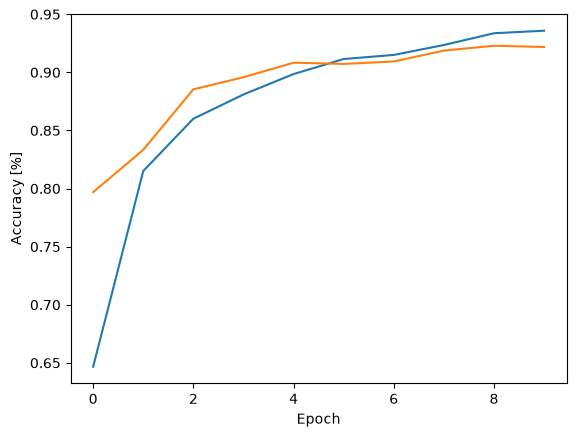

In [19]:
metrics = history.history
plt.plot(history.epoch,metrics['accuracy'])
plt.plot(history.epoch,metrics['val_accuracy'])
plt.xlabel("Epoch")
plt.ylabel("Accuracy [%]")
plt.show()